# Query a cube, account for the work

**Terrain & Earth observation · 15–25 minutes · learning companion**

Earth in the Browser: 30 lessons connect Zarr/SQL foundations with AR6 projections, GeoTessera embeddings, Global FTW predictions and SeasFire/LexCube historical fire studios.

**Learning question:** How does a time filter change the number of chunks touched?

**Source project:** [JupyterLite-zarr-sql-views](https://github.com/jltobias/JupyterLite-zarr-sql-views).

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/capabilities.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Construct a tiny 3-time, 4-cell synthetic cube. Model two time steps per chunk and sum one slice; this models access costs without claiming to read actual Zarr files.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Slice sums: [6, 46, 86] ; two times per conceptual chunk
Conceptual chunk reads for a synthetic cube | chunks: {'time 0': 1, 'time 1': 1, 'time 0–2': 2}


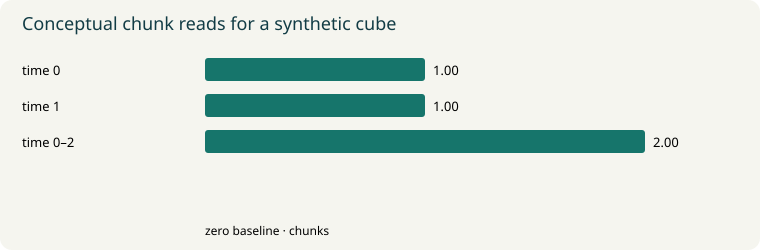

In [2]:
cube = [[10*t+c for c in range(4)] for t in range(3)]
queries = {'time 0':[0], 'time 1':[1], 'time 0–2':[0,1,2]}
chunks = {name:len({t//2 for t in times}) for name,times in queries.items()}
print('Slice sums:', [sum(row) for row in cube], '; two times per conceptual chunk')
bars(chunks, 'Conceptual chunk reads for a synthetic cube', 'chunks')


## Interpret the result

A narrower query can touch fewer chunks, but adjacent slices may share one. Actual storage costs depend on layout, encoding, network and cache.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Compare chunk sizes 1 and 3 for these queries. Explain why no single chunk layout is best for every access pattern.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Add an experiment: intervals and missing coverage

**Learning question:** How can a zero, a missing value and a short final interval change a cube summary?

This original **Python analogue of SQL** groups four invented cell-period rows. It does not read Zarr, execute SQL or load LexCube. The source course supplies actual SQL and LexCube capabilities through the links below. The two cells have equal teaching weight; weather is weighted by observed cell-days, not geographical area.

Retain one row per declared cell-period: two cells × two periods here. Missing measurements use `None`; do not drop their rows. This complete declared grid makes the possible-support denominator meaningful. A sparse or filtered table needs an independently declared expected grid before calculating complete-support coverage; the rows remaining in that table cannot establish the expected support by themselves.

Predict the summaries for intervals [2021-12-19, 2021-12-27) and [2021-12-27, 2022-01-01). Derive 8 and 5 days from the end dates, including the final closing boundary. `burned_ha` is extensive hectares per cell-period; sum observed values without multiplying by duration. `temperature_c` is an intensive period mean in invented degrees Celsius; multiply by duration and divide by that variable's covered cell-days. (The source SeasFire temperature uses kelvin.) `None` is unavailable, while numeric zero remains observed. Inputs must be finite numbers or None; each row's period must name a positive-duration interval.

In SQL terms these are separate `IS NOT NULL` masks, a guarded `SUM(burned_ha)`, and `SUM(temperature_c * days) / SUM(days)` over observed temperature rows. A truthiness filter would incorrectly drop zero. An all-missing variable must yield unknown, with coverage zero.


Synthetic half-open intervals [start, end): [('2021-12-19', '2021-12-27'), ('2021-12-27', '2022-01-01')] ; durations in days: [8, 5]
Invented cell-period rows: [{'cell': 'A', 'period': 0, 'burned_ha': 0, 'temperature_c': 20}, {'cell': 'A', 'period': 1, 'burned_ha': 4, 'temperature_c': None}, {'cell': 'B', 'period': 0, 'burned_ha': None, 'temperature_c': 30}, {'cell': 'B', 'period': 1, 'burned_ha': 6, 'temperature_c': 10}]
burned_ha: 10.000 ha observed total; 3/4 rows; coverage 18/26 cell-days
temperature_c: 21.429 C weighted mean; 3/4 rows; coverage 21/26 cell-days
Zero is observed; None is missing. Each variable has its own mask. Incomplete coverage is not an estimate of the missing support.
Synthetic cube: variable-specific coverage | cell-days; possible support is a reference: {'burned_ha': 18, 'temperature_c': 21, 'possible support': 26}


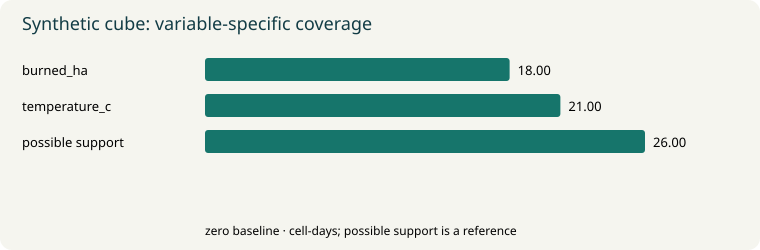

In [3]:
from datetime import date

# Invented support for two cells: eight days, then a shorter five-day final bin.
intervals = [('2021-12-19', '2021-12-27'), ('2021-12-27', '2022-01-01')]
interval_days = [(date.fromisoformat(end)-date.fromisoformat(start)).days
                 for start, end in intervals]
cube_rows = [
    {'cell': 'A', 'period': 0, 'burned_ha': 0,    'temperature_c': 20},
    {'cell': 'A', 'period': 1, 'burned_ha': 4,    'temperature_c': None},
    {'cell': 'B', 'period': 0, 'burned_ha': None, 'temperature_c': 30},
    {'cell': 'B', 'period': 1, 'burned_ha': 6,    'temperature_c': 10},
]

def summarize_support(rows, durations):
    possible_days = sum(durations[row['period']] for row in rows)
    result = {}
    for variable in ['burned_ha', 'temperature_c']:
        observed = [row for row in rows if row[variable] is not None]
        covered_days = sum(durations[row['period']] for row in observed)
        # Extensive hectares already describe a cell-period: do not multiply by days.
        total = sum(row[variable] for row in observed) if observed else None
        # An intensive weather mean uses its own observed cell-day support.
        weighted_mean = (sum(row[variable]*durations[row['period']] for row in observed)
                         / covered_days) if covered_days else None
        result[variable] = {'covered_cell_days': covered_days,
                            'possible_cell_days': possible_days,
                            'observed_rows': len(observed),
                            'observed_total': total if variable == 'burned_ha' else None,
                            'weighted_mean': weighted_mean if variable == 'temperature_c' else None}
    return result

support = summarize_support(cube_rows, interval_days)
print('Synthetic half-open intervals [start, end):', intervals, '; durations in days:', interval_days)
print('Invented cell-period rows:', cube_rows)
for variable, stats in support.items():
    metric = stats['observed_total'] if variable == 'burned_ha' else stats['weighted_mean']
    unit = 'ha observed total' if variable == 'burned_ha' else 'C weighted mean'
    value_text = f'{metric:.3f}' if metric is not None else 'unknown'
    print(f"{variable}: {value_text} {unit}; {stats['observed_rows']}/{len(cube_rows)} rows; "
          f"coverage {stats['covered_cell_days']}/{stats['possible_cell_days']} cell-days")
print('Zero is observed; None is missing. Each variable has its own mask. Incomplete coverage is not an estimate of the missing support.')
coverage_bars = {name: stats['covered_cell_days'] for name, stats in support.items()}
coverage_bars['possible support'] = support['burned_ha']['possible_cell_days']
bars(coverage_bars,
     'Synthetic cube: variable-specific coverage',
     'cell-days; possible support is a reference')


## Interpret the coverage result

The default observed burned total is **10 ha**, covering **18/26 cell-days** and three of four rows. It is not a complete-support total or a unique burned footprint. The observed temperature mean is **450/21 = 21.429 °C**, covering **21/26 cell-days** and three rows. Its unweighted row mean would be 20 °C. Neither denominator may be borrowed from the other variable. The zero burned value contributes eight observed days. Missing values are excluded without inventing zeros; the printed summaries and coverage SVG follow current inputs. The possible-support bar is a reference for the declared grid, not another measured variable.

## Change one thing

Replace both interval endpoints with a continuous pair of eight-day bins and predict the changed weather weighting. Then restore the dates and set every `burned_ha` to `None`: the burned total must print **unknown**, with **0/26 cell-days**; temperature remains unchanged. Finally set every temperature to None: its mean is unknown with zero coverage. A true observed zero total and an unknown total need different captions. Do not fill gaps to make a prettier time cube.

The source SeasFire studio retains shorter year-end intervals and variable-specific masks. Its burned area is historical hectares, not active-fire fronts; weather, vegetation and fire have different support. Seasonal associations or lags do not establish causes, forecasts, smoke exposure, crop losses or health effects. No actual SeasFire values enter this exercise.


## Thirty source lessons: Earth in the Browser
James L. Tobias / jltobias, *Earth in the Browser*, inspected 2026-11-01, [commit `9a191f1fd30c`](https://github.com/jltobias/JupyterLite-zarr-sql-views/blob/9a191f1fd30c40e09b48b9f92a9b5fdd9676509e/README.md). Every Run URL below is transcribed from that README. They open the external source course. HTTP GET returned 200 on 2026-11-01 for the entry documents; query-target execution, graphics and providers were not certified. The original atlas chunk exercise above is preserved; the coverage exercise is additive.

### 01–12 · Foundations
Browser experiments, Zarr chunks/SQL rows, observed DE Africa water, linked maps/cubes, C3S warming levels, synthetic heat/coasts/air/water/food questions, STAC/GeoLibre and an evidence-led capstone.

| Lesson and investigation | Source Lab |
|---|---|
| 01 · A browser is a scientific workspace | [Run 01](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=01_start_here.ipynb) |
| 02 · From Zarr chunks to SQL rows | [Run 02](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=02_zarr_sql.ipynb) |
| 03 · Lake Ngami: water observations and missing evidence | [Run 03](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=03_deafrica_water.ipynb) |
| 04 · 2D maps, 3D maps, and a space–time cube | [Run 04](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=04_maps_and_cubes.ipynb) |
| 05 · C3S Atlas: scenarios, warming levels, and model spread | [Run 05](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=05_c3s_atlas.ipynb) |
| 06 · Global heat questions, African heat laboratory | [Run 06](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=06_heat_stress.ipynb) |
| 07 · Sea-level rise and the meaning of a 3D scene | [Run 07](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=07_coastal_scenes.ipynb) |
| 08 · Air quality: a map is not an exposure estimate | [Run 08](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=08_air_quality.ipynb) |
| 09 · Water quality: from optical signal to a testable hypothesis | [Run 09](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=09_water_quality.ipynb) |
| 10 · Food and water insecurity | [Run 10](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=10_food_water.ipynb) |
| 11 · STAC discovery and GeoLibre handoff | [Run 11](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=11_stac_geolibre.ipynb) |
| 12 · Capstone: an evidence-led climate story | [Run 12](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=12_capstone.ipynb) |

### 13–16 · AR6 port-city studio
Archive/chunk access, gauge proxies, regional grids/3D/time cubes and threshold uncertainty. Conditional projections are not gauge observations or flood probabilities; one workflow's percentiles are not the assessed p-box. Scenarios have no assigned probabilities; no rates or first-crossing dates are supported.

| Lesson and investigation | Source Lab |
|---|---|
| 13 · Open the AR6 archive without downloading the world | [Run 13](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=13_ar6_archive.ipynb) |
| 14 · Five port cities, four tide-gauge proxies | [Run 14](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=14_ar6_port_cities.ipynb) |
| 15 · Regional grids, 3D maps, and sea-level time cubes | [Run 15](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=15_ar6_grid_maps.ipynb) |
| 16 · Threshold questions without false flood probabilities | [Run 16](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=16_ar6_uncertainty.ipynb) |

### 17–21 · GeoTessera studio
Annual vectors/quantization, cosine similarity/SQL, shared PCA/3D, clusters/transfer and annual differences. Learned representations and observation counts are not hazard measurements, class probabilities or model confidence.

| Lesson and investigation | Source Lab |
|---|---|
| 17 · GeoTessera: from satellite years to embedding vectors | [Run 17](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=17_tessera_embeddings.ipynb) |
| 18 · Similarity search: vectors, maps, Zarr and SQL | [Run 18](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=18_tessera_similarity.ipynb) |
| 19 · PCA colors and a three-dimensional embedding space | [Run 19](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=19_tessera_pca.ipynb) |
| 20 · Clusters, transfer and the need for independent labels | [Run 20](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=20_tessera_clusters.ipynb) |
| 21 · Annual embedding differences and coastal evidence | [Run 21](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=21_tessera_change.ipynb) |

### 22–25 · Global FTW studio
Discovery, three-class probability/SQL/3D, polygons/confidence/selection and annual food–water questions. Predicted fields are not legal parcels or ownership. Pixel probability differs from the separate 500 m confidence layer; annual differences need independent validation.

| Lesson and investigation | Source Lab |
|---|---|
| 22 · Global FTW: discover fields, probabilities and confidence | [Run 22](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=22_ftw_discovery.ipynb) |
| 23 · FTW probability cubes: maps, SQL and 3D | [Run 23](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=23_ftw_probability_sql.ipynb) |
| 24 · Field polygons, confidence and selection bias | [Run 24](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=24_ftw_fields_confidence.ipynb) |
| 25 · Annual field predictions and food–water questions | [Run 25](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=25_ftw_change_food_water.ipynb) |

### 26–30 · SeasFire and LexCube studio
Discovery/masks/units, historical fire maps/SQL/animation, seasons/lags, actual LexCube slicing and linked comparisons. Source uses two 16×16 native windows in 2001–2021; masks and shorter year-end intervals matter. Hectares differ from duration-weighted weather means. No forecast or causal/health claim is supported.

| Lesson and investigation | Source Lab |
|---|---|
| 26 · SeasFire: read the cube before reading the fire | [Run 26](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=26_seasfire_discovery.ipynb) |
| 27 · Burned area: maps, SQL and a moving season | [Run 27](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=27_seasfire_maps_sql.ipynb) |
| 28 · Seasons, anomalies and lagged relationships | [Run 28](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=28_seasfire_seasons_lags.ipynb) |
| 29 · LexCube: slice a real fire cube in the browser | [Run 29](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=29_seasfire_lexcube.ipynb) |
| 30 · LexCube comparisons: fire, dryness and evidence | [Run 30](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=30_seasfire_lexcube_compare.ipynb) |

Lessons 29–30 run **LexCube 2.0.1** in the source JupyterLite kernel, separately from the SQL/deck.gl map/cube explorer. See [corresponding source, GPL license and Pyodide adaptation](https://jltobias.github.io/JupyterLite-zarr-sql-views/vendor/lexcube/README.md). The documented adaptation uses WebAssembly-compatible dependencies and disables a native psutil memory diagnostic; this index embeds none of its wheel, frontend or source archive. Source first launch downloads runtimes/dependencies; 3D needs WebGL2. Native data preparation remains separate. The local atlas exercises use only standard-library Python and IPython display.
## Earth studio citations, rights and use

- Alonso, L., Gans, F., Karasante, I., et al. (2024). *SeasFire Cube: A Global Dataset for Seasonal Fire Modeling in the Earth System*, **v0.4**, [Zenodo](https://doi.org/10.5281/zenodo.13834057), **CC BY 4.0**. Karasante, I., et al. (2025), *SeasFire cube — a multivariate dataset for global wildfire modeling*, Scientific Data **12**, 368, [paper](https://doi.org/10.1038/s41597-025-04546-3). Credit the SeasFire consortium/ESA; EC JRC/GWIS burned area; ECMWF/Copernicus ERA5 weather; NASA MODIS MOD13C1 v6 NDVI; ESA EarthCODE/CloudFerro Zarr hosting. VPD and cell area are derived, not independent observations. [GWIS](https://gwis.jrc.ec.europa.eu/) · [ERA5](https://doi.org/10.24381/cds.adbb2d47) · [MOD13C1 v6](https://doi.org/10.5067/MODIS/MOD13C1.006).
- Söchting, M., Scheuermann, G., Montero, D., & Mahecha, M. D. (2025). *Interactive Earth system data cube visualization in Jupyter notebooks*. Big Earth Data **9(2)**, **321–335**. [DOI](https://doi.org/10.1080/20964471.2025.2471646). **LexCube 2.0.1**, Maximilian Söchting and contributors, **GPL-3.0-or-later**; credit RSC4Earth/Leipzig University and ESA DeepESDL/DFG NFDI4Earth. [Upstream](https://github.com/msoechting/lexcube) · [source adaptation](https://jltobias.github.io/JupyterLite-zarr-sql-views/vendor/lexcube/README.md). The source course's ISC license does not relicense LexCube.
- Robinson, C., Muhawenayo, G., Khanal, S., et al. (2026). *The first global agricultural field boundary map at 10 m resolution*. [arXiv:2605.11055](https://doi.org/10.48550/arXiv.2605.11055). [Global Fields of the World](https://source.coop/ftw/global-data), alpha predictions **2024/2025**, **CC BY 4.0**. Credit Taylor Geospatial and collaborators, Microsoft AI for Good, participating universities, Copernicus Sentinel-2 and Source Cooperative/Radiant Earth. No predictions or polygons are copied here.
- Feng, Z., et al. (2025; revised 2026). *TESSERA: Temporal Embeddings of Surface Spectra for Earth Representation and Analysis*. [arXiv:2506.20380](https://doi.org/10.48550/arXiv.2506.20380). Source uses **TESSERA v1.1 / dClimate**. Credit TESSERA/University of Cambridge and collaborators, dClimate global inference/hosting and GeoTessera contributors. [Terms](https://github.com/ucam-eo/tessera/blob/master/aup.md) explicitly declare data **CC0**, with advisory ethical guidance and inconsistent legacy CC-BY wording retained upstream; GeoTessera code is MIT. No embeddings or model weights are copied here.
- Garner, G. G., et al. (2021). *IPCC AR6 Sea Level Projections*, **v20210809**, [dataset](https://doi.org/10.5281/zenodo.5914709), **CC BY 4.0**. Also credit Fox-Kemper et al. (2021), WG1 Chapter 9, [DOI](https://doi.org/10.1017/9781009157896.011), and Kopp et al. (2023), FACTS v1.0, GMD **16**, 7461–7489, [DOI](https://doi.org/10.5194/gmd-16-7461-2023). Thank the projection authors, supporting funding agencies and NASA Sea Level Change Team for the projection tool. The [pinned Rutgers-ESSP guide](https://github.com/Rutgers-ESSP/IPCC-AR6-Sea-Level-Projections/tree/8ee75128d8f6d9a8ba9825f47c92d11955d0651e) and [NASA tool](https://sealevel.nasa.gov/ipcc-ar6-sea-level-projection-tool) retain assessed-product guidance. No projection extract is copied here.

The source adaptation credits [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC. The source course's original code, lessons and SVG artwork remain **ISC**; its data and LexCube have the separate terms above. This index uses original synthetic fixtures, MIT code and CC BY 4.0 prose/figures, without copying source datasets, code or artwork. Complete provider notices and transformations are in the [pinned source credits](https://github.com/jltobias/JupyterLite-zarr-sql-views/blob/9a191f1fd30c40e09b48b9f92a9b5fdd9676509e/book/credits.md), [SeasFire guide](https://github.com/jltobias/JupyterLite-zarr-sql-views/blob/9a191f1fd30c40e09b48b9f92a9b5fdd9676509e/book/seasfire.md), [FTW guide](https://github.com/jltobias/JupyterLite-zarr-sql-views/blob/9a191f1fd30c40e09b48b9f92a9b5fdd9676509e/book/fields.md), [GeoTessera guide](https://github.com/jltobias/JupyterLite-zarr-sql-views/blob/9a191f1fd30c40e09b48b9f92a9b5fdd9676509e/book/embeddings.md) and [AR6 guide](https://github.com/jltobias/JupyterLite-zarr-sql-views/blob/9a191f1fd30c40e09b48b9f92a9b5fdd9676509e/book/sea-level.md). No institutional endorsement is implied.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-zarr-sql-views](https://github.com/jltobias/JupyterLite-zarr-sql-views).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-zarr-sql-views/blob/9a191f1fd30c40e09b48b9f92a9b5fdd9676509e/README.md); inspected 2026-11-01, commit `9a191f1fd30c40e09b48b9f92a9b5fdd9676509e`. Original course: James L. Tobias / jltobias, *Earth in the Browser*. All thirty exact Lab links are grouped above.

Original atlas chunk and coverage exercises are synthetic Python analogues, not actual Zarr/SQL or LexCube execution. Source lessons/artwork and upstream Zarr SQL Views are ISC; LexCube 2.0.1 is GPL-3.0-or-later. Source datasets retain separate terms. AR6 conditional projections are not flood probabilities; embeddings are not hazard measurements; FTW predictions are not ownership; SeasFire associations are not forecasts or causal effects. No source data, code, imagery or binaries are copied. Native preparation and source graphics/runtime requirements remain separate.

Representative documented views and source documentation (separate from the local exercises):

- [Open source learning hub](https://jltobias.github.io/JupyterLite-zarr-sql-views/) — Choose among the source project learning experiences. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Read source Book](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/intro.html) — Read the original project course and its own source notes. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Explore source extruded map](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=tessera_lagos&mode=columns) — Explore original extruded geography; height encodings require interpretation. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Run source JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html) — Run the source Python lessons; the interactive Earth lab is a separate explorer. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Interactive Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) — Explore source datasets and their provenance. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Synthetic water proxy map](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=water&mode=map) — Synthetic reflectance, not drinking-water safety. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Synthetic coastal scene](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=coast&mode=scene) — Synthetic terrain, not an inundation forecast. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [AR6 port-city studio](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/sea-level.html) — Read the source studio, its interpretation limits and provider credits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [GeoTessera embedding studio](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/embeddings.html) — Read the source studio, its interpretation limits and provider credits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Global FTW field studio](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/fields.html) — Read the source studio, its interpretation limits and provider credits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [SeasFire and LexCube studio](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/seasfire.html) — Read the source studio, its interpretation limits and provider credits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Historical SeasFire: northern Ghana and neighboring savannas — 2D map](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=seasfire_ghana&mode=map) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Historical SeasFire: northern Ghana and neighboring savannas — 3D columns](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=seasfire_ghana&mode=columns) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Historical SeasFire: northern Ghana and neighboring savannas — time cube](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=seasfire_ghana&mode=cube) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Historical SeasFire: northern Ghana and neighboring savannas — value scene](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=seasfire_ghana&mode=scene) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [FTW predicted fields: Senegal teaching window — 2D map](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=ftw_senegal&mode=map) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [FTW predicted fields: Senegal teaching window — 3D columns](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=ftw_senegal&mode=columns) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [FTW predicted fields: Senegal teaching window — time cube](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=ftw_senegal&mode=cube) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [FTW predicted fields: Senegal teaching window — value scene](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=ftw_senegal&mode=scene) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [GeoTessera annual similarity: Lagos teaching window — 2D map](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=tessera_lagos&mode=map) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [GeoTessera annual similarity: Lagos teaching window — time cube](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=tessera_lagos&mode=cube) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Conditional AR6 projection: Lagos regional grid — 2D map](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=ar6_lagos&mode=map) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Conditional AR6 projection: Lagos regional grid — 3D columns](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=ar6_lagos&mode=columns) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Conditional AR6 projection: Lagos regional grid — time cube](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/?dataset=ar6_lagos&mode=cube) — Source view of a bounded window; consult studio provenance, units, masks and interpretation limits. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [LexCube source and Pyodide adaptation](https://jltobias.github.io/JupyterLite-zarr-sql-views/vendor/lexcube/README.md) — Corresponding source and GPL-3.0-or-later license for source-course LexCube 2.0.1; no LexCube is embedded in this index. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)

**Runtime budget:** both original local exercises contain fewer than 100 values and normally complete within seconds; allow 60 seconds per cell while Python first loads. The source lab uses Zarrita/Arrow/DuckDB-WASM/deck.gl; its notebooks use Pyodide-compatible packages, with extra dependencies for LexCube. SQL filters the already loaded window; it is not automatic remote predicate pushdown. Normal source builds use their own checked-in derivatives; native bounded data refresh remains separate. This index adds no dependencies, network calls or authentication.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
